# Day 9: Missing & Malformed Data Handling
> **Course:** C-DAC PGCP-AI Data Analytics  
> **Topic:** Missing Data Taxonomy, Simple Imputation, Outlier Capping & Duplicate Resolution  
> **Approach:** Basics to Applied, Simple & Clear  

---

## 📌 Table of Contents
1. [Missing Data Taxonomy: MCAR, MAR, MNAR](#1-missing-data-taxonomy-mcar-mar-mnar)
2. [Imputation Strategies: KNN, Iterative (MICE), Rolling](#2-imputation-strategies-knn-iterative-mice-rolling)
3. [Outlier Handling: Winsorization & Clipping](#3-outlier-handling-winsorization--clipping)
4. [Duplicate Detection & Entity Resolution Basics](#4-duplicate-detection--entity-resolution-basics)
5. [Quick Interview Traps & Viva Tips](#5-quick-interview-traps--viva-tips)

---

In [1]:
# Simple imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.mstats import winsorize
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
import difflib

# Clean plotting settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (7, 4)
plt.rcParams['figure.dpi'] = 110

print("All libraries imported successfully!")

All libraries imported successfully!


---
## 1. Missing Data Taxonomy: MCAR, MAR, MNAR

Missing data is not just "blank cells"—there is always a **reason** why it is missing. We divide missing data into **3 simple types**:

| Type | Full Form | Simple Meaning | Real-Life Example | Is it safe to drop rows? |
| :--- | :--- | :--- | :--- | :--- |
| **MCAR** | Missing Completely at Random | Pure accident / coin toss. Nothing caused it. | A paper test got blown away by the wind. | **YES.** `df.dropna()` is safe. |
| **MAR** | Missing at Random | Missingness is related to **another known column**. | In a survey, people in IT forgot to enter daily hours. | **NO.** Dropping causes bias. Impute using known columns! |
| **MNAR** | Missing Not at Random | Missingness is caused by the **value itself**. | People with very low marks or very high salary hid their answer. | **NO.** Dropping or simple filling causes heavy distortion. |

---

In [2]:
# 1.1 Simple Dataset Demonstrating MCAR, MAR, MNAR
df_students = pd.DataFrame({
    'Student': ['Aarav', 'Bhavna', 'Chetan', 'Divya', 'Esha', 'Farhan', 'Gita', 'Harsh'],
    'Department': ['HR', 'IT', 'HR', 'IT', 'HR', 'IT', 'HR', 'IT'],
    # MCAR: Random missing scores due to system network glitch
    'Score_MCAR': [82.0, np.nan, 75.0, 91.0, np.nan, 88.0, 79.0, 94.0],
    # MAR: Missingness happens mostly in the IT department
    'Score_MAR': [82.0, np.nan, 75.0, np.nan, 80.0, np.nan, 79.0, 94.0],
    # MNAR: Students with low scores (< 70) refused to submit them
    'Score_MNAR': [82.0, 88.0, 75.0, 91.0, 80.0, 94.0, np.nan, np.nan]
})

print("--- Students Dataset with Missing Types ---")
display(df_students)

# Count missing values per column
print("\n--- Missing Count per Column ---")
print(df_students.isna().sum())

--- Students Dataset with Missing Types ---


,Student,Department,Score_MCAR,Score_MAR,Score_MNAR
0,Aarav,HR,82.0,82.0,82.0
1,Bhavna,IT,NaN,NaN,88.0
2,Chetan,HR,75.0,75.0,75.0
3,Divya,IT,91.0,NaN,91.0
4,Esha,HR,NaN,80.0,80.0
5,Farhan,IT,88.0,NaN,94.0
6,Gita,HR,79.0,79.0,NaN
7,Harsh,IT,94.0,94.0,NaN



--- Missing Count per Column ---
Student       0
Department    0
Score_MCAR    2
Score_MAR     3
Score_MNAR    2
dtype: int64


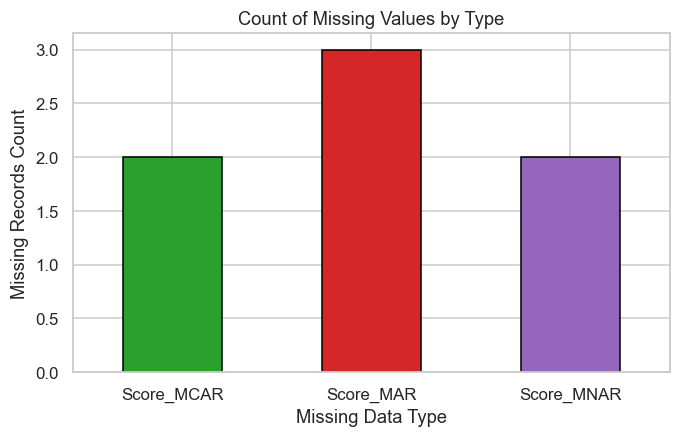

In [3]:
# 1.2 Simple Visualization of Missingness
missing_counts = df_students[['Score_MCAR', 'Score_MAR', 'Score_MNAR']].isna().sum()

plt.figure(figsize=(7, 4))
missing_counts.plot(kind='bar', color=['#2ca02c', '#d62728', '#9467bd'], edgecolor='black')
plt.title('Count of Missing Values by Type')
plt.ylabel('Missing Records Count')
plt.xlabel('Missing Data Type')
plt.xticks(rotation=0)
plt.show()

---
## 2. Imputation Strategies: KNN, Iterative (MICE), Rolling

When data is missing, we can fill it in (**imputation**):

1. **Simple Mean/Median (`fillna`):** Replaces blanks with the column average.
   * *Problem:* Fills every blank with the exact same number, which flattens data variability.
2. **KNN Imputer (K-Nearest Neighbors):**
   * Looks at other rows that are most **similar** (neighbors) and takes their average.
   * Great when rows share similar features (e.g. similar age & experience).
3. **Iterative Imputer (MICE - Chained Equations):**
   * Uses linear regression to predict the missing column from all other columns.
   * Great when columns have strong linear relationships.
4. **Rolling Window Imputation (Time-Series):**
   * Uses forward-fill (`ffill`) or moving average of previous days.
   * Essential for sequential dates or sensor readings.

---

In [4]:
# 2.1 KNN and Iterative (MICE) Imputation on Employee Data
df_emp = pd.DataFrame({
    'Experience_Years': [1, 2, 3, 5, 7, 8, 10, 12],
    'Age': [23, 24, 26, 28, 32, 34, 38, 42],
    # Salary has missing values at index 2 and index 5
    'Salary': [32000, 36000, np.nan, 55000, 72000, np.nan, 95000, 115000]
})

print("--- Original Employee Data (with missing Salary) ---")
display(df_emp)

# A. KNN Imputation (looks at nearest 2 rows)
knn = KNNImputer(n_neighbors=2)
emp_knn_imputed = knn.fit_transform(df_emp)
df_emp['Salary_KNN'] = np.round(emp_knn_imputed[:, 2], 0)

# B. Iterative Imputation (MICE - predicts Salary using Experience & Age)
mice = IterativeImputer(max_iter=10, random_state=42)
emp_mice_imputed = mice.fit_transform(df_emp[['Experience_Years', 'Age', 'Salary']])
df_emp['Salary_MICE'] = np.round(emp_mice_imputed[:, 2], 0)

# C. Simple Mean Imputation for comparison
df_emp['Salary_Mean'] = np.round(df_emp['Salary'].fillna(df_emp['Salary'].mean()), 0)

print("\n--- Comparison of Imputed Salaries ---")
display(df_emp[['Experience_Years', 'Age', 'Salary', 'Salary_Mean', 'Salary_KNN', 'Salary_MICE']])

--- Original Employee Data (with missing Salary) ---

,Experience_Years,Age,Salary
0,1,23,32000.0
1,2,24,36000.0
2,3,26,NaN
3,5,28,55000.0
4,7,32,72000.0
5,8,34,NaN
6,10,38,95000.0
7,12,42,115000.0



--- Comparison of Imputed Salaries ---


,Experience_Years,Age,Salary,Salary_Mean,Salary_KNN,Salary_MICE
0,1,23,32000.0,32000.0,32000.0,32000.0
1,2,24,36000.0,36000.0,36000.0,36000.0
2,3,26,NaN,67500.0,45500.0,44934.0
3,5,28,55000.0,55000.0,55000.0,55000.0
4,7,32,72000.0,72000.0,72000.0,72000.0
5,8,34,NaN,67500.0,83500.0,80004.0
6,10,38,95000.0,95000.0,95000.0,95000.0
7,12,42,115000.0,115000.0,115000.0,115000.0


--- Time-Series Sales Imputation ---


,Sales,Sales_FFill,Sales_Rolling_Mean
Date,,,
2026-10-01,120.0,120.0,120.0
2026-10-02,135.0,135.0,135.0
2026-10-03,NaN,135.0,127.5
2026-10-04,150.0,150.0,150.0
2026-10-05,NaN,150.0,150.0
2026-10-06,180.0,180.0,180.0
2026-10-07,195.0,195.0,195.0
2026-10-08,210.0,210.0,210.0


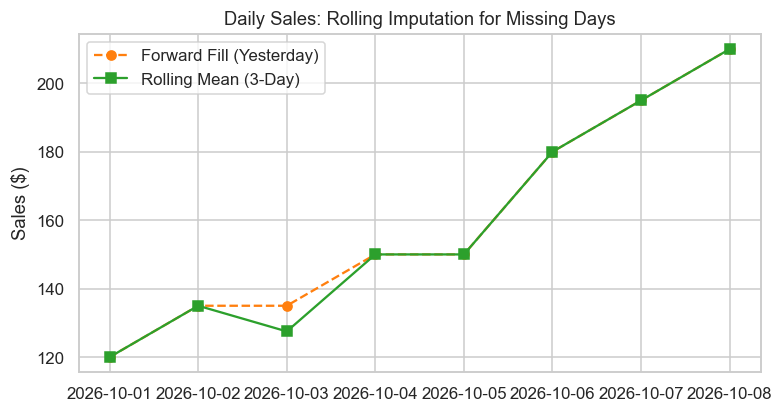

In [5]:
# 2.2 Rolling Window Imputation for Time-Series Data
dates = pd.date_range('2026-10-01', periods=8, freq='D')
daily_sales = [120, 135, np.nan, 150, np.nan, 180, 195, 210]

df_sales_ts = pd.DataFrame({'Date': dates, 'Sales': daily_sales}).set_index('Date')

# Forward-fill (uses yesterday's value)
df_sales_ts['Sales_FFill'] = df_sales_ts['Sales'].ffill()

# Rolling mean (uses average of last 3 days)
df_sales_ts['Sales_Rolling_Mean'] = df_sales_ts['Sales'].fillna(
    df_sales_ts['Sales'].rolling(window=3, min_periods=1).mean()
)

print("--- Time-Series Sales Imputation ---")
display(df_sales_ts)

# Simple plot of time-series imputation
plt.figure(figsize=(8, 4))
plt.plot(df_sales_ts.index, df_sales_ts['Sales_FFill'], 'o--', label='Forward Fill (Yesterday)', color='#ff7f0e')
plt.plot(df_sales_ts.index, df_sales_ts['Sales_Rolling_Mean'], 's-', label='Rolling Mean (3-Day)', color='#2ca02c')
plt.title('Daily Sales: Rolling Imputation for Missing Days')
plt.ylabel('Sales ($)')
plt.legend()
plt.show()

---
## 3. Outlier Handling: Winsorization & Clipping

### What is an outlier?
An outlier is an extreme number that is way too large or way too small compared to everyone else (e.g. Someone typed salary as `850,000` instead of `85,000`).

### Two Simple Ways to Handle Outliers Without Deleting Rows:
1. **Clipping (`df.clip`):**
   * Put hard limits: minimum = lower boundary, maximum = upper boundary.
   * Any number bigger than maximum becomes the maximum. Any number smaller becomes the minimum.
2. **Winsorization (`scipy.stats.mstats.winsorize`):**
   * Statistical capping: caps the top 5% and bottom 5% to the 95th and 5th percentiles.
   * **Super advantage:** You do not lose any rows ($N$ stays the same), and the **median stays unchanged**!

---

--- Outlier Comparison Table ---


,Raw_Salary,Clipped_Salary,Winsorized_Salary
0,48000,48000,48000
1,52000,52000,52000
2,55000,55000,55000
3,58000,58000,58000
4,62000,62000,62000
5,68000,68000,68000
6,72000,72000,72000
7,75000,75000,75000
8,82000,82000,82000
9,500000,90000,500000


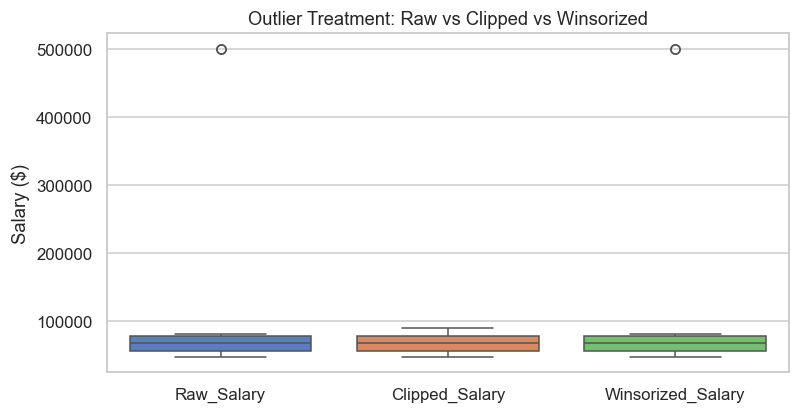

In [6]:
# 3.1 Outlier Clipping and Winsorization Example
# Normal salaries around 50,000 to 90,000 + 2 huge typo outliers (500,000 and 750,000)
salaries_raw = [48000, 52000, 55000, 58000, 62000, 68000, 72000, 75000, 82000, 500000, 750000]

df_salary = pd.DataFrame({'Raw_Salary': salaries_raw})

# 1. Clipping: Cap between 40,000 and 90,000
df_salary['Clipped_Salary'] = df_salary['Raw_Salary'].clip(lower=40000, upper=90000)

# 2. Winsorization: Cap top 10%
df_salary['Winsorized_Salary'] = winsorize(df_salary['Raw_Salary'], limits=[0.0, 0.10])

print("--- Outlier Comparison Table ---")
display(df_salary)

# Side-by-side boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_salary[['Raw_Salary', 'Clipped_Salary', 'Winsorized_Salary']])
plt.title('Outlier Treatment: Raw vs Clipped vs Winsorized')
plt.ylabel('Salary ($)')
plt.show()

---
## 4. Duplicate Detection & Entity Resolution Basics

In real business datasets, duplicates happen due to:
* People typing names differently (`"Sundar Pichai"` vs `"Pichai, Sundar"`).
* Small spelling mistakes or typos (`"Microsoft"` vs `"Microsft"`).
* Trailing spaces or lowercase letters (`"Google"` vs `"google "`).

### 3 Simple Levels of Duplicates:
1. **Exact Duplicate:** Every single column matches.
   * Solution: `df.drop_duplicates()`
2. **Subset Duplicate:** The ID or Email matches.
   * Solution: `df.drop_duplicates(subset=['email'])`
3. **Fuzzy Duplicate (Entity Resolution):** The spelling is slightly different, but it refers to the same company or person!
   * Solution: String cleaning + Python `difflib.get_close_matches()`.

---

In [7]:
# 4.1 Exact, Subset, and Fuzzy Duplicate Handling
df_customers = pd.DataFrame({
    'CustomerID': [101, 102, 103, 104, 105, 106],
    'Name': ['Alice Smith', 'Bob Jones', 'Alice Smith', 'Sundar Pichai', 'Sundar K. Pichai', 'Microsft Corp'],
    'Email': ['alice@mail.com', 'bob@mail.com', 'alice@mail.com', 'sundar@google.com', 'sundar@google.com', 'contact@ms.com'],
    'Company': ['Apple', 'Amazon', 'Apple', 'Google', 'Google LLC', 'Microsoft']
})

print("--- Original Raw Customers (6 records) ---")
display(df_customers)

# 1. Exact Duplicate Drop (Drop row 2 because row 0 is identical)
df_no_exact = df_customers.drop_duplicates(subset=['Name', 'Email', 'Company'])
print(f"\nAfter dropping exact duplicates: {len(df_no_exact)} records")

# 2. Subset Duplicate Drop by Email (Keeps first occurrence of each email)
df_unique_email = df_customers.drop_duplicates(subset=['Email'], keep='first')
print(f"After dropping duplicate emails: {len(df_unique_email)} records")
display(df_unique_email[['CustomerID', 'Name', 'Email', 'Company']])

# 3. Simple Fuzzy Entity Resolution for Messy Company Names
clean_companies = ['Apple', 'Amazon', 'Google', 'Microsoft']

def match_company(name):
    # Find closest match from clean master list
    matches = difflib.get_close_matches(name, clean_companies, n=1, cutoff=0.5)
    return matches[0] if matches else name

df_customers['Clean_Company'] = df_customers['Company'].apply(match_company)

print("\n--- Resolved Customer Company Entities ---")
display(df_customers[['Name', 'Company', 'Clean_Company']])

--- Original Raw Customers (6 records) ---


,CustomerID,Name,Email,Company
0,101,Alice Smith,alice@mail.com,Apple
1,102,Bob Jones,bob@mail.com,Amazon
2,103,Alice Smith,alice@mail.com,Apple
3,104,Sundar Pichai,sundar@google.com,Google
4,105,Sundar K. Pichai,sundar@google.com,Google LLC
5,106,Microsft Corp,contact@ms.com,Microsoft



After dropping exact duplicates: 5 records
After dropping duplicate emails: 4 records


,CustomerID,Name,Email,Company
0,101,Alice Smith,alice@mail.com,Apple
1,102,Bob Jones,bob@mail.com,Amazon
3,104,Sundar Pichai,sundar@google.com,Google
5,106,Microsft Corp,contact@ms.com,Microsoft



--- Resolved Customer Company Entities ---


,Name,Company,Clean_Company
0,Alice Smith,Apple,Apple
1,Bob Jones,Amazon,Amazon
2,Alice Smith,Apple,Apple
3,Sundar Pichai,Google,Google
4,Sundar K. Pichai,Google LLC,Google
5,Microsft Corp,Microsoft,Microsoft


---
## 5. Quick Interview Traps & Viva Tips

| Viva Question | Simple 1-Line Answer |
| :--- | :--- |
| **When is it safe to use `dropna()`?** | Only under **MCAR** (Missing Completely at Random), because it does not create bias. |
| **Why is mean imputation often bad?** | It artificially shrinks data variance and destroys relationships with other columns. |
| **Why do we need to scale features before KNN Imputer?** | Because Euclidean distance is sensitive to scale; large numbers (like Salary) will overpower small numbers (like Age). |
| **Does Winsorization change the median?** | **No!** Capping the top/bottom 5% leaves the middle 50th percentile (median) completely unchanged. |
| **What is Lookahead Bias in time-series?** | Using future values (like `bfill`) to fill past missing dates, which leaks future information. |

---
**Module Completed:** Day 9 Missing & Malformed Data Handling  
**Author:** abs6187 (`23f2000876@ds.study.iitm.ac.in`)
